# Exploratory Data Analysis

In [1]:
from pyspark.sql import SparkSession
import os

spark = SparkSession.builder \
    .appName("Final_Project_EDA") \
    .getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/22 11:36:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/22 11:36:49 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


In [2]:
DATA_FILEPATH = '/standard/ds7200-apt4c/team2/ptb_superclass_v4'

In [3]:
df = spark.read.parquet(DATA_FILEPATH)
df.select("ecg_id").show(5)

+------+
|ecg_id|
+------+
|   217|
|   290|
|   441|
|   733|
|   800|
+------+
only showing top 5 rows


In [11]:
len(df.columns)

2070

### Data Types

In [12]:
from collections import Counter

dtype_counts = Counter(dtype for col, dtype in df.dtypes)

print(dtype_counts)

Counter({'double': 1837, 'int': 228, 'string': 5})


### Descriptive Statistics

#### Outcome variables: Diagnostic Codes - NORM, MI, STTC, CD, HYP

Normal ECG

In [27]:
df.groupby('NORM').count().show()

+----+-----+
|NORM|count|
+----+-----+
|   1| 9513|
|   0|11865|
+----+-----+



Myocardial Infarction

In [16]:
df.groupby('MI').count().show()

+---+-----+
| MI|count|
+---+-----+
|  1| 5466|
|  0|15912|
+---+-----+



ST/T Change

In [17]:
df.groupby('STTC').count().show()

+----+-----+
|STTC|count|
+----+-----+
|   1| 5230|
|   0|16148|
+----+-----+



Conduction Disturbance

In [18]:
df.groupby('CD').count().show()

+---+-----+
| CD|count|
+---+-----+
|  1| 4892|
|  0|16486|
+---+-----+



Hypertrophy

In [19]:
df.groupby('HYP').count().show()

+---+-----+
|HYP|count|
+---+-----+
|  1| 2644|
|  0|18734|
+---+-----+



#### Age

In [20]:
df.groupby('age').count().orderBy('age').show(100)

+----+-----+
| age|count|
+----+-----+
| 2.0|    1|
| 3.0|    2|
| 4.0|    2|
| 5.0|    2|
| 6.0|    1|
| 7.0|    1|
| 8.0|    3|
| 9.0|    2|
|10.0|    3|
|11.0|    4|
|12.0|    2|
|13.0|    7|
|14.0|   11|
|15.0|   23|
|16.0|   28|
|17.0|   41|
|18.0|  168|
|19.0|  179|
|20.0|   88|
|21.0|   75|
|22.0|   76|
|23.0|   77|
|24.0|   70|
|25.0|  102|
|26.0|   89|
|27.0|  115|
|28.0|  106|
|29.0|   92|
|30.0|  118|
|31.0|  116|
|32.0|  123|
|33.0|  131|
|34.0|  123|
|35.0|  141|
|36.0|  169|
|37.0|  184|
|38.0|  173|
|39.0|  180|
|40.0|  226|
|41.0|  217|
|42.0|  211|
|43.0|  229|
|44.0|  214|
|45.0|  239|
|46.0|  264|
|47.0|  287|
|48.0|  269|
|49.0|  284|
|50.0|  307|
|51.0|  361|
|52.0|  364|
|53.0|  378|
|54.0|  516|
|55.0|  506|
|56.0|  479|
|57.0|  513|
|58.0|  448|
|59.0|  487|
|60.0|  509|
|61.0|  521|
|62.0|  498|
|63.0|  478|
|64.0|  515|
|65.0|  541|
|66.0|  521|
|67.0|  552|
|68.0|  535|
|69.0|  473|
|70.0|  462|
|71.0|  454|
|72.0|  459|
|73.0|  414|
|74.0|  366|
|75.0|  454|

#### Sex

In [9]:
df.groupby('sex').count().show()

+---+-----+
|sex|count|
+---+-----+
|  1|10442|
|  0|11353|
+---+-----+



### Diagnosis by Sex

In [12]:
from pyspark.sql.functions import asc
from pyspark.sql import functions as F

df.createOrReplaceTempView("diagnoses")

diagnosis_by_sex = spark.sql("SELECT sex, SUM(NORM) as NORM, SUM(MI) as MI, SUM(STTC) as STTC, SUM(CD) as CD, SUM(HYP) as HYP \
                          FROM diagnoses \
                          GROUP BY sex \
                          ORDER BY sex asc")
diagnosis_by_sex.show(20)

+---+----+----+----+----+----+
|sex|NORM|  MI|STTC|  CD| HYP|
+---+----+----+----+----+----+
|  0|4386|3406|2565|2996|1519|
|  1|5127|2060|2665|1896|1125|
+---+----+----+----+----+----+



/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


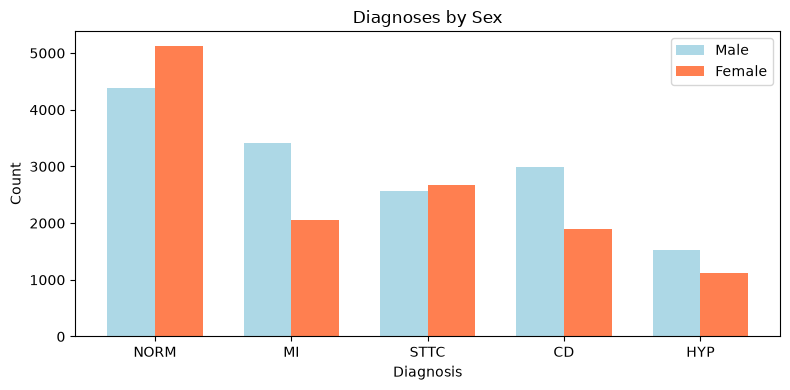

In [15]:
import matplotlib.pyplot as plt

diagnosis_plot = diagnosis_by_sex.transpose().toPandas()

fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(diagnosis_plot))
w = 0.35
ax.bar([i - w/2 for i in x], diagnosis_plot['0'], w, label='Male', color='#ADD8E6')
ax.bar([i + w/2 for i in x], diagnosis_plot['1'], w, label='Female', color='#FF7F50')
ax.set_xticks(x)
ax.set_xticklabels(diagnosis_plot['key'])
ax.set_xlabel('Diagnosis')
ax.set_ylabel('Count')
ax.legend()
ax.set_title('Diagnoses by Sex')
plt.tight_layout()
plt.show()